In [1]:
import numpy as np
import os
import matplotlib.pyplot as plt

In [2]:
def load_data(folder):
    x_train: np.ndarray = np.load(os.path.join(folder, 'x_train.npy'))
    y_train: np.ndarray = np.load(os.path.join(folder, 'y_train.npy'))
    x_test: np.ndarray = np.load(os.path.join(folder, 'x_test.npy'))
    y_test: np.ndarray = np.load(os.path.join(folder, 'y_test.npy'))
    return x_train, y_train, x_test, y_test

In [3]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))


class LogisticRegression:
    def __init__(self, dim=2, threshold=0.5):
        rng = np.random.default_rng(seed=0)
        self.w = rng.normal(size=(dim, 1)) / np.sqrt(dim)
        self.b = np.zeros((1,))
        self.threshold = threshold
        
    def predict(self, x, probs=False):
        # x - np.array размерности [N, dim]
        #     Массив входных признаков.
        assert x.shape[1] == self.w.shape[0], \
            "Размерность экземпляров данных не соответствует ожидаемой: " + \
            f"ожидалось x.shape[1]={self.w.shape[0]}, но было получено x.shape[1]={x.shape[1]}"
        
        x = x.dot(self.w) + self.b  # logits
        p = sigmoid(x)  # probabilities
        if probs:
            return p
        return np.array(p > self.threshold).astype('int32')
        
    def fit(self, x, y, iters=1000, lr=0.01):
        # x - np.array размерности [N, dim]
        #     Массив входных признаков.
        # y - np.array размернсоти [N]
        #     Массив меток (правильных ответов).
        assert len(x) == len(y), \
            "Количество экземпляров в массиве X не равно количеству меток в массиве Y. " + \
            f"Полученные размеры: len(X) = {len(x)}, len(Y) = {len(y)}."
        assert x.shape[1] == self.w.shape[0], \
            "Размерность экземпляров данных не соответствует ожидаемой: " + \
            f"ожидалось x.shape[1]={self.w.shape[0]}, но было получено x.shape[1]={x.shape[1]}"
        # Алгоритм градиентного спуска.
        # Минимизируется бинарная кросс-энтропия.
        y = y.reshape(-1, 1)
        for i in range(iters):
            preds = self.predict(x, probs=True)
            self.w -= lr * np.mean(x.T.dot(preds - y), axis=1, keepdims=True)
            self.b -= lr * np.mean(preds - y, axis=0)
        return self

## 1. Применение логистической регрессии (несбалансированные данные)

### 1.1 Создание и обучение логистической регрессии

In [4]:
# Указание: производить нормализацию данных не нужно, это часть задания.
x_train, y_train, x_test, y_test = load_data('dataset1')

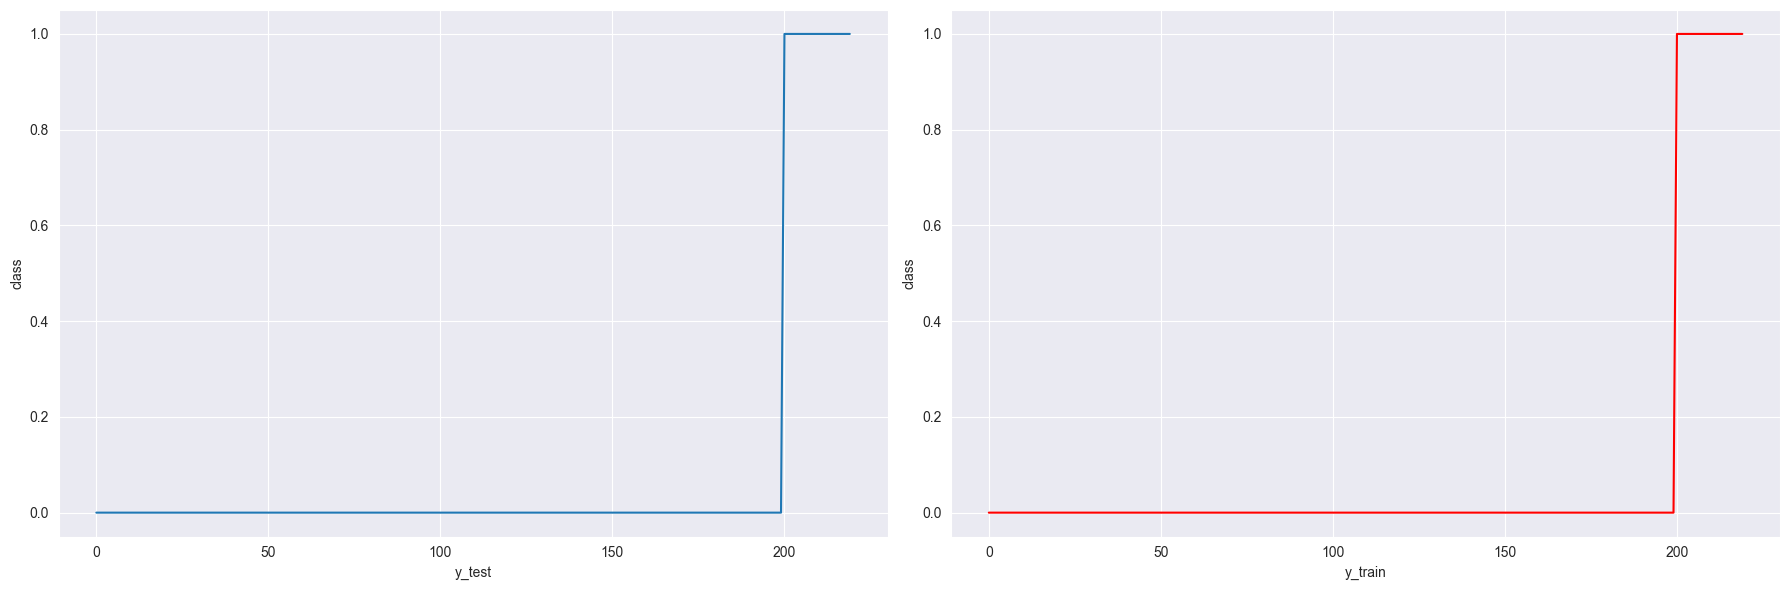

Отношение классов друг к другу:
Class1 / Class2 = 0.09090909090909091
Class1 / Class2 = 0.09090909090909091


In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))
ax1.plot(y_test)
ax1.set_xlabel("y_test")
ax1.set_ylabel("class")
ax2.plot(y_train, color='red')
ax2.set_xlabel("y_train")
ax2.set_ylabel("class")
# plt.plot(y_test)
plt.tight_layout()
plt.show()

print("Отношение классов друг к другу:")
print("Class1 / Class2 =", np.count_nonzero(y_test) / len(y_test))
print("Class1 / Class2 =", np.count_nonzero(y_train) / len(y_train))

Дисбаланс достаточно высокий

In [6]:
# Создайте модель логистической регрессии и обучите её, используя метод fit.
logreg = LogisticRegression(x_train.shape[1])
logreg.fit(x_train, y_train)
y_pred = logreg.predict(x_test)

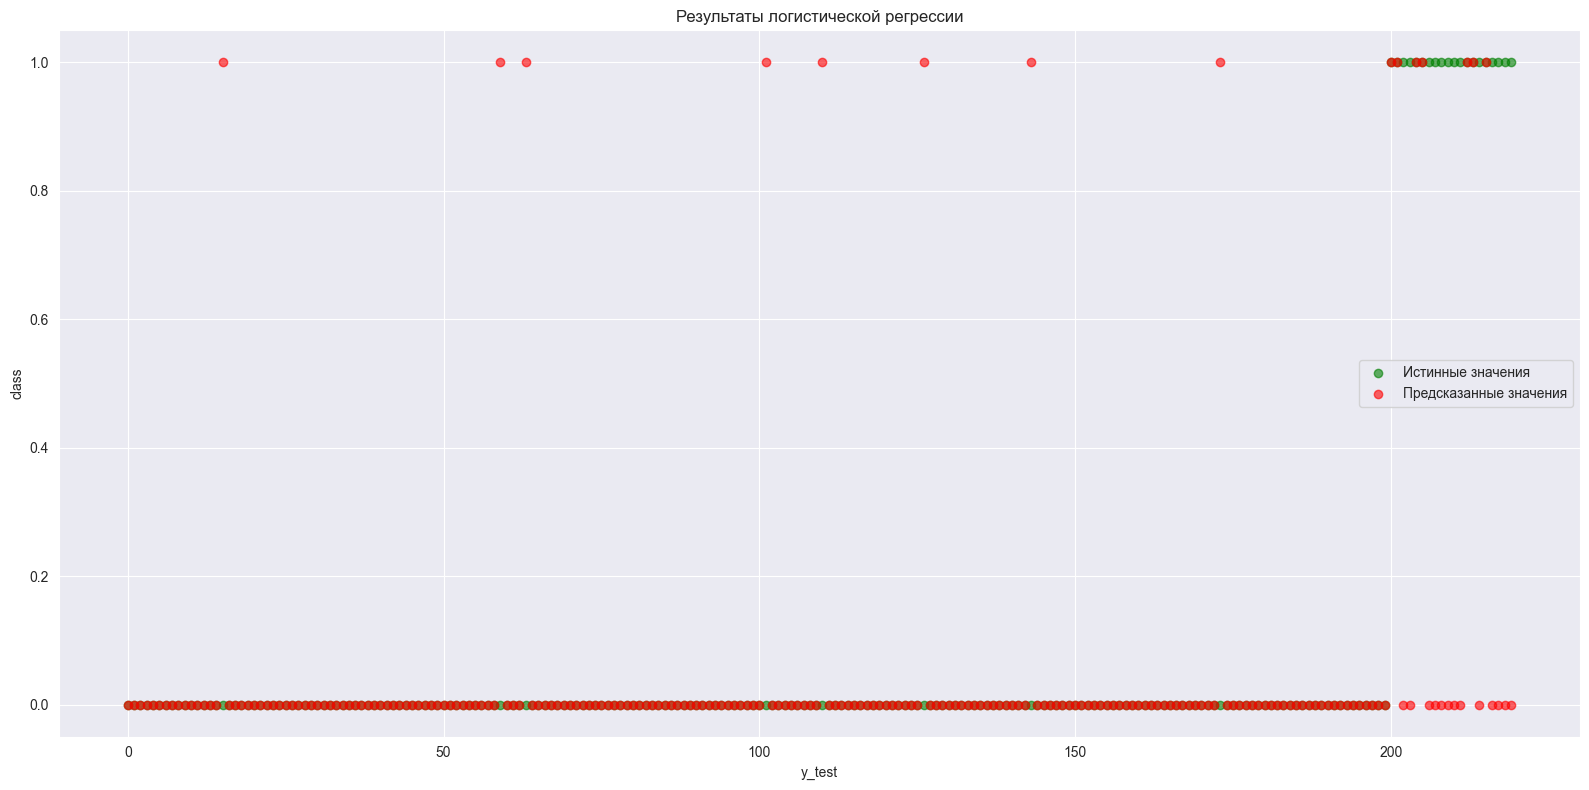

In [7]:
fig = plt.figure(figsize=(16, 8))
axes = plt.axes()
axes.set_title("Результаты логистической регрессии")
axes.set_xlabel("y_test")
axes.set_ylabel("class")
plt.scatter(np.arange(y_test.size), y_test, alpha=0.6, color="green")
plt.scatter(np.arange(y_pred.size), y_pred, alpha=0.6, color="red")
plt.legend(("Истинные значения", "Предсказанные значения"))
plt.tight_layout()
plt.show()

In [8]:
# Получите предсказания на тестовой выборке и оцените точность модели, 
# используя accuracy_score из пакета SciKit-Learn.
from sklearn.metrics import accuracy_score

print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.9045454545454545


### 1.2 Анализ качества модели

In [9]:
# Допишите класс "глупого классификатора", что всегда предсказывает класс `0`. 

class DummyClassifier:
    def __init__(self):
        print('Hello, brother!')
        
    def predict(self, x):
        # x - numpy массив размерности [N, dim]
        # Должен возвращаться массив N предсказаний
        return np.zeros(x.shape[0], dtype=np.int32).reshape((-1, 1))

In [10]:
# Оцените точность "глупого классификатора", объясните результат.
dummy = DummyClassifier()

dummy_pred = dummy.predict(x_test)

print("Accuracy:", accuracy_score(y_test, dummy_pred))

Hello, brother!
Accuracy: 0.9090909090909091


"Аккуратность" буквально равна доле класса 0 в выборке, поскольку она считается как количество правильных ответов (априори - количество записей класса 0), делённое на количество всех ответов. Метрика не подходит для несбалансированных данных и искажает реальное качество классификации.

In [11]:
# Используйте дополнительные метрики (f1-score, recall, precision) из пакета sklearn для анализа "глупого классификатора".
from sklearn.metrics import f1_score, recall_score, precision_score

print("f1_score:", f1_score(y_test, dummy_pred))
print("recall_score:", recall_score(y_test, dummy_pred))
print("precision_score:", precision_score(y_test, dummy_pred))

f1_score: 0.0
recall_score: 0.0
precision_score: 0.0


C:\Users\musai\PycharmProjects\NeuralNetworksSem7\venv\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [12]:
# Используя те же метрики, проанализируйте обученную вами модель логистической регрессии.

print("f1_score:", f1_score(y_test, y_pred))
print("recall_score:", recall_score(y_test, y_pred))
print("precision_score:", precision_score(y_test, y_pred))

f1_score: 0.4
recall_score: 0.35
precision_score: 0.4666666666666667


In [13]:
# Объясните результат, описав его комментариями в этой клетке.

# Нулевые значения у тупого классификатора объясняются тем, что по умолчанию метрики бинарной классификации считаются для класса 1 (который он вообще не может предсказать). Отсюда и значения для логистической регрессии (её результаты на тестовом наборе можно увидеть на графике выше). Важно, что Accuracy вычисляется по обоим классам сразу (так как TP для класса 0 = TN для класса 1 и у accuracy_score нет параметра pos_label).

### 1.3 Анализ набора данных

In [14]:
# Посчитайте количество экземпляров данных для каждого класса.
counts = np.unique_counts(np.concat((y_test, y_train)))

print(f"Количество элементов каждого класса во всём наборе данных:\nClass 0: {counts[1][0]}\nClass 1: {counts[1][1]}")

Количество элементов каждого класса во всём наборе данных:
Class 0: 400
Class 1: 40


In [15]:
# Предложите способ улучшения качества модели. Подсказка: добавление дубликатов в данные.
# Указание: не изменяйте тестовую выборку.

# Есть несколько вариантов. Первый - oversampling, добавление лишних примеров на миноритарном классе. Второй - баланскировка весами классов. Третий и наиболее простой - изменение порога разделения классов (например, не 0.5, а 0.1).

In [16]:
# Создайте и обучите модель с использованием предложенных наработок.

def sigmoid(x):
    return 1 / (1 + np.exp(-x))


class LogisticRegressionWeights:
    def __init__(self, dim=2, threshold=0.5, class_weight=None):
        rng = np.random.default_rng(seed=0)
        self.w = rng.normal(size=(dim, 1)) / np.sqrt(dim)
        self.b = np.zeros((1,))
        self.threshold = threshold
        self.class_weight = class_weight

    def predict(self, x, probs=False):
        # x - np.array размерности [N, dim]
        #     Массив входных признаков.
        assert x.shape[1] == self.w.shape[0], \
            "Размерность экземпляров данных не соответствует ожидаемой: " + \
            f"ожидалось x.shape[1]={self.w.shape[0]}, но было получено x.shape[1]={x.shape[1]}"

        x = x.dot(self.w) + self.b  # logits
        p = sigmoid(x)  # probabilities
        if probs:
            return p
        return np.array(p > self.threshold).astype('int32')

    def _get_sample_weights(self, y, class_weight=None, sample_weight=None):
        """
        Возвращает веса для каждого объекта формы [N, 1].

        Можно передать:
        1) sample_weight - массив весов для каждого объекта
        2) class_weight - словарь {0: weight_0, 1: weight_1} или строку 'balanced'
        """

        y = np.asarray(y).reshape(-1)
        n = y.shape[0]

        if sample_weight is None:
            sw = np.ones((n, 1), dtype=np.float64)
        else:
            sw = np.asarray(sample_weight, dtype=np.float64).reshape(-1, 1)
            if sw.shape[0] != n:
                raise ValueError(
                    "Длина sample_weight не совпадает с количеством объектов. "
                    f"Получено: len(sample_weight)={sw.shape[0]}, n={n}."
                )

        cw = class_weight if class_weight is not None else self.class_weight

        if cw is None:
            return sw

        # class_weight='balanced'
        if isinstance(cw, str):
            if cw != "balanced":
                raise ValueError("Если class_weight является строкой, поддерживается только 'balanced'.")

            classes, counts = np.unique(y, return_counts=True)
            n_classes = len(classes)

            if n_classes == 0:
                return sw

            # Формула в sklearn:
            # weight_c = n_samples / (n_classes * n_samples_c)
            weight_map = {
                c: n / (n_classes * count)
                for c, count in zip(classes, counts)
            }

            class_weights = np.array(
                [weight_map[c] for c in y],
                dtype=np.float64
            ).reshape(-1, 1)

            return sw * class_weights

        # class_weight={0: ..., 1: ...}
        if isinstance(cw, dict):
            class_weights = np.ones((n, 1), dtype=float)

            for i, label in enumerate(y):
                if label in cw:
                    class_weights[i, 0] = cw[label]
                elif int(label) in cw:
                    class_weights[i, 0] = cw[int(label)]
                elif float(label) in cw:
                    class_weights[i, 0] = cw[float(label)]
                else:
                    class_weights[i, 0] = 1.0

            return sw * class_weights

        raise ValueError("class_weight должен быть None, 'balanced' или словарем {класс: вес}.")

    def fit(self, x, y, iters=1000, lr=0.01, class_weight=None, sample_weight=None):
        # x - np.array размерности [N, dim]
        #     Массив входных признаков.
        # y - np.array размернсоти [N]
        #     Массив меток (правильных ответов).
        assert len(x) == len(y), \
            "Количество экземпляров в массиве X не равно количеству меток в массиве Y. " + \
            f"Полученные размеры: len(X) = {len(x)}, len(Y) = {len(y)}."
        assert x.shape[1] == self.w.shape[0], \
            "Размерность экземпляров данных не соответствует ожидаемой: " + \
            f"ожидалось x.shape[1]={self.w.shape[0]}, но было получено x.shape[1]={x.shape[1]}"
        # Алгоритм градиентного спуска.
        # Минимизируется бинарная кросс-энтропия.
        y = y.reshape(-1, 1)

        sample_weights = self._get_sample_weights(
            y,
            class_weight=class_weight,
            sample_weight=sample_weight
        )

        # Нормировка градиента по сумме весов.
        denom = float(sample_weights.sum())

        if denom <= 0:
            raise ValueError("Сумма весов должна быть больше нуля.")

        for i in range(iters):
            preds = self.predict(x, probs=True)
            error = (preds - y) * sample_weights
            self.w -= lr * x.T.dot(error) / denom
            self.b -= lr * np.sum(error, axis=0) / denom

        return self


def oversampling(X: np.ndarray, y: np.ndarray):
    return np.concat((np.concat((X, X[200:, :])), X[200:, :])), np.concat((np.concat((y, y[200:])), y[200:]))

x_train_ov, y_train_ov = oversampling(x_train, y_train)
print(y_train_ov)

[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [17]:
print("Accuracy:", accuracy_score(y_test, y_pred))

logreg_weights = LogisticRegressionWeights(x_train.shape[1], class_weight="balanced")
logreg_weights.fit(x_train, y_train)
y_pred_weights = logreg_weights.predict(x_test)
print("Accuracy:", accuracy_score(y_test, y_pred_weights))

logreg_threshold = LogisticRegression(x_train.shape[1], threshold=0.1)
logreg_threshold.fit(x_train, y_train)
y_pred_threshold = logreg_threshold.predict(x_test)
print("Accuracy:", accuracy_score(y_test, y_pred_threshold))

logreg_ov = LogisticRegression(x_train.shape[1], threshold=0.1)
logreg_ov.fit(x_train_ov, y_train_ov)
y_pred_ov = logreg_ov.predict(x_test)
print("Accuracy:", accuracy_score(y_test, y_pred_ov))

Accuracy: 0.9045454545454545
Accuracy: 0.9545454545454546
Accuracy: 0.9272727272727272
Accuracy: 0.9318181818181818


In [18]:
# Оцените качество новой модели, используя метрики из пакета sklearn.metrics. 
# Указание: постарайтесь сбалансировать данные таким образом, чтобы новая модель была ощутимо лучше старой.

print("Базовая модель:")
print("\tAccuracy:", accuracy_score(y_test, y_pred))
print("\tf1_score:", f1_score(y_test, y_pred))
print("\trecall_score:", recall_score(y_test, y_pred))
print("\tprecision_score:", precision_score(y_test, y_pred))
print()
print("Модель с весами:")
print("\tAccuracy:", accuracy_score(y_test, y_pred_weights))
print("\tf1_score:", f1_score(y_test, y_pred_weights))
print("\trecall_score:", recall_score(y_test, y_pred_weights))
print("\tprecision_score:", precision_score(y_test, y_pred_weights))
print()
print("Модель с изменённым порогом:")
print("\tAccuracy:", accuracy_score(y_test, y_pred_threshold))
print("\tf1_score:", f1_score(y_test, y_pred_threshold))
print("\trecall_score:", recall_score(y_test, y_pred_threshold))
print("\tprecision_score:", precision_score(y_test, y_pred_threshold))
print()
print("Модель с oversampling:")
print("\tAccuracy:", accuracy_score(y_test, y_pred_ov))
print("\tf1_score:", f1_score(y_test, y_pred_ov))
print("\trecall_score:", recall_score(y_test, y_pred_ov))
print("\tprecision_score:", precision_score(y_test, y_pred_ov))

Базовая модель:
	Accuracy: 0.9045454545454545
	f1_score: 0.4
	recall_score: 0.35
	precision_score: 0.4666666666666667

Модель с весами:
	Accuracy: 0.9545454545454546
	f1_score: 0.7619047619047619
	recall_score: 0.8
	precision_score: 0.7272727272727273

Модель с изменённым порогом:
	Accuracy: 0.9272727272727272
	f1_score: 0.6
	recall_score: 0.6
	precision_score: 0.6

Модель с oversampling:
	Accuracy: 0.9318181818181818
	f1_score: 0.6341463414634146
	recall_score: 0.65
	precision_score: 0.6190476190476191


#### Лучшая модель - модель с весами

## 2. Применение логистической регрессии (нелинейные данные)

In [19]:
x_train, y_train, x_test, y_test = load_data('dataset2')

print(f"x_train: {x_train.shape}, x_test: {x_test.shape}")

x_train: (300, 2), x_test: (100, 2)


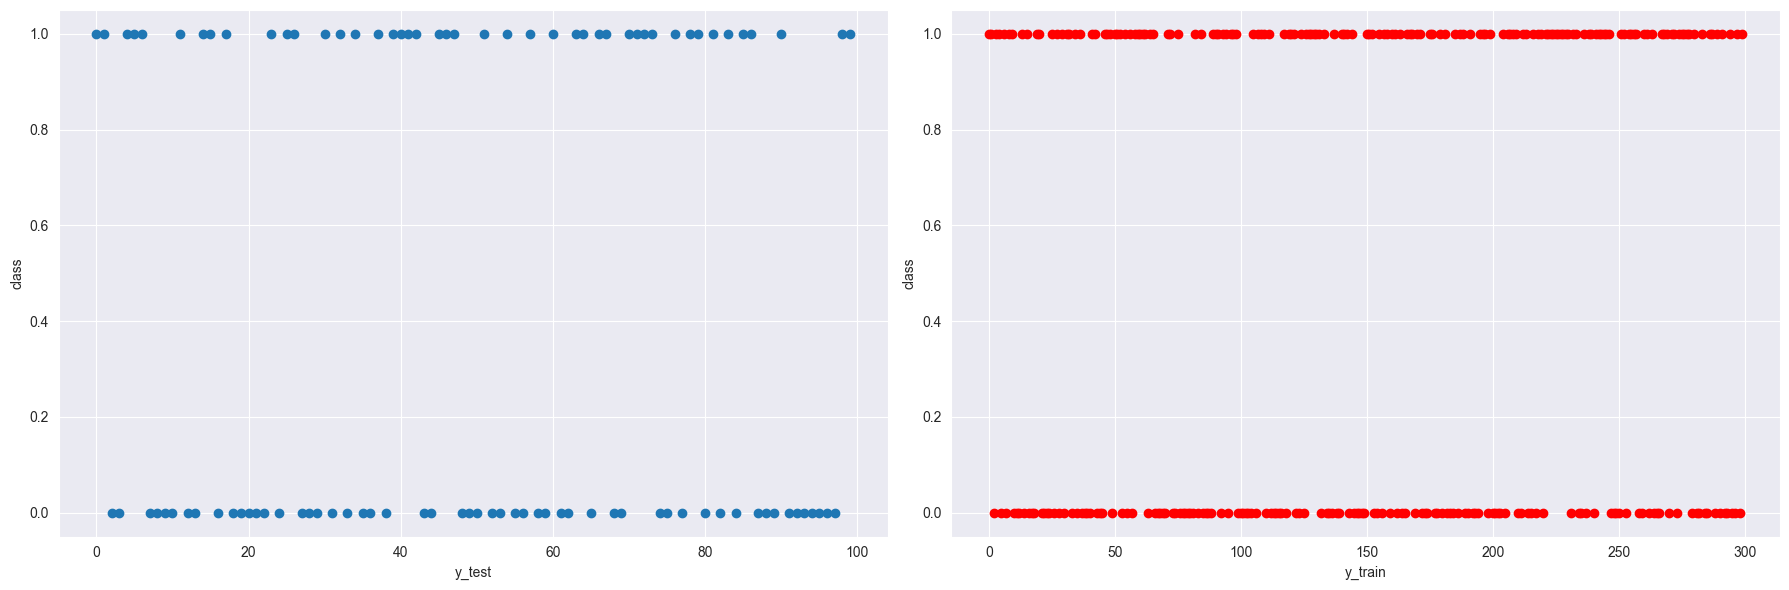

Отношение классов друг к другу:
Class1 / Class2 = 0.45
Class1 / Class2 = 0.5166666666666667


In [20]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))
ax1.scatter(np.arange(y_test.size), y_test)
ax1.set_xlabel("y_test")
ax1.set_ylabel("class")
ax2.scatter(np.arange(y_train.size), y_train, color="red")
ax2.set_xlabel("y_train")
ax2.set_ylabel("class")
# plt.plot(y_test)
plt.tight_layout()
plt.show()

print("Отношение классов друг к другу:")
print("Class1 / Class2 =", np.count_nonzero(y_test) / len(y_test))
print("Class1 / Class2 =", np.count_nonzero(y_train) / len(y_train))

In [21]:
# Создайте и обучите модель но этом наборе данных.
logreg = LogisticRegression(x_train.shape[1])
logreg.fit(x_train, y_train)
y_pred = logreg.predict(x_test)

In [22]:
# Проанализируйте качество модели.
print("Базовая модель:")
print("\tAccuracy:", accuracy_score(y_test, y_pred))
print("\tf1_score:", f1_score(y_test, y_pred))
print("\trecall_score:", recall_score(y_test, y_pred))
print("\tprecision_score:", precision_score(y_test, y_pred))

Базовая модель:
	Accuracy: 0.57
	f1_score: 0.6194690265486725
	recall_score: 0.7777777777777778
	precision_score: 0.5147058823529411


In [23]:
# FEATURE ENGINEERING: попробуйте применить на исходных данных разные нелинейные функции (sin, tanh, ...).
# Объедините трансформированные данные с исходными (важно: количество экземпляров в x_train не должно увеличиться).
def add_nonlinear_features(X, n_fourier=100, seed=42):
    X = np.asarray(X, dtype=np.float64)
    x1 = X[:, :1]
    x2 = X[:, 1:2]

    feats = [X]  # исходные признаки

    # Полиномиальные признаки
    feats += [x1**2, x2**2, x1 * x2,
              x1**3, x2**3, x1**2 * x2, x1 * x2**2]

    # Тригонометрия от исходных признаков и их комбинаций
    feats += [np.sin(X), np.cos(X),
              np.sin(x1 + x2), np.cos(x1 + x2),
              np.sin(x1 - x2), np.cos(x1 - x2),
              np.sin(x1 * x2), np.cos(x1 * x2)]

    # Гиперболические функции
    feats += [np.tanh(X), np.tanh(x1 * x2)]

    # Полярные координаты (радиус и угол)
    r = np.sqrt(x1**2 + x2**2)
    theta = np.arctan2(x2, x1)
    feats += [r, r**2, r**3,
              np.sin(r), np.cos(r),
              np.sin(theta), np.cos(theta),
              np.sin(r * theta), np.cos(r * theta)]

    # Случайные признаки Фурье (аппроксимация RBF-ядра).
    rng = np.random.default_rng(seed)
    W = rng.normal(size=(X.shape[1], n_fourier))
    b = rng.uniform(0.0, 2 * np.pi, size=(1, n_fourier))
    feats += [np.sin(X @ W + b), np.cos(X @ W + b)]

    return np.hstack(feats)

x_train_fe = add_nonlinear_features(x_train)
x_test_fe  = add_nonlinear_features(x_test)

# Нормализация: статистики считаем на train, применяем и к test
mu  = x_train_fe.mean(axis=0, keepdims=True)
std = x_train_fe.std(axis=0, keepdims=True)
std[std == 0.0] = 1.0
x_train_fe = (x_train_fe - mu) / std
x_test_fe  = (x_test_fe - mu) / std

print(f"Количество экземпляров: {x_train_fe.shape[0]} (не изменилось)")
print(f"Размерность признаков: {x_train.shape[1]} -> {x_train_fe.shape[1]}")

Количество экземпляров: 300 (не изменилось)
Размерность признаков: 2 -> 231


In [24]:
# Создайте и обучите модель с использованием наработок.
logreg_fe = LogisticRegression(dim=x_train_fe.shape[1])
logreg_fe.fit(x_train_fe, y_train, iters=5000, lr=0.1)
y_pred_fe = logreg_fe.predict(x_test_fe)

logreg_weights = LogisticRegressionWeights(x_train_fe.shape[1], class_weight="balanced")
logreg_weights.fit(x_train_fe, y_train, iters=5000, lr=0.1)
y_pred_weights_fe = logreg_weights.predict(x_test_fe)

C:\Users\musai\AppData\Local\Temp\ipykernel_49812\1636522969.py:4: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp(-x))


In [25]:
# Оцените качество новой модели, используя метрики из пакета sklearn.metrics. 
# Указание: постарайтесь добиться точности в 100%!
print("Базовая модель:")
print("\tAccuracy:", accuracy_score(y_test, y_pred_fe))
print("\tf1_score:", f1_score(y_test, y_pred_fe))
print("\trecall_score:", recall_score(y_test, y_pred_fe))
print("\tprecision_score:", precision_score(y_test, y_pred_fe))

print("Модель с весами:")
print("\tAccuracy:", accuracy_score(y_test, y_pred_weights_fe))
print("\tf1_score:", f1_score(y_test, y_pred_weights_fe))
print("\trecall_score:", recall_score(y_test, y_pred_weights_fe))
print("\tprecision_score:", precision_score(y_test, y_pred_weights_fe))

Базовая модель:
	Accuracy: 1.0
	f1_score: 1.0
	recall_score: 1.0
	precision_score: 1.0
Модель с весами:
	Accuracy: 1.0
	f1_score: 1.0
	recall_score: 1.0
	precision_score: 1.0


## 3. Доп. задания (любое на выбор, опционально)

### 3.1 'Упрощение' логистической регрессии

Сложность: легко.

In [26]:
"""
Модифицируйте класс логистической регрессии так, чтобы в нём не использовалась сигмоида.
То есть вывод о предсказанном классе должен делаться на основе значений "до сигмоиды".
Вспомогательная ссылка: https://en.wikipedia.org/wiki/Logit
"""

def arctg(x):
    return np.arctan(x) / np.pi * 2

class LogisticRegression:
    def __init__(self, dim=2):
        rng = np.random.default_rng(seed=0)
        self.w = rng.normal(size=(dim, 1)) / np.sqrt(dim)
        self.b = np.zeros((1,))

    def predict(self, x, probs=False):
        logits = x.dot(self.w) + self.b
        if probs:
            return arctg(logits)  # заменил сигмоиду на арктангенс

        # Арктангенс (да и сигмоида) монотонно возрастает и равен нулю в разделяющей гиперплоскости. Это позволяет определять класс по знаку логита.
        return (logits > 0).astype('int32')

    def fit(self, x, y, iters=1000, lr=0.01):
        y = y.reshape(-1, 1)
        for i in range(iters):
            # градиент кросс-энтропии требует вероятностей — сигмоиду заменил арктангенс
            preds = arctg(x.dot(self.w) + self.b)
            self.w -= lr * np.mean(x.T.dot(preds - y), axis=1, keepdims=True)
            self.b -= lr * np.mean(preds - y, axis=0)

        return self

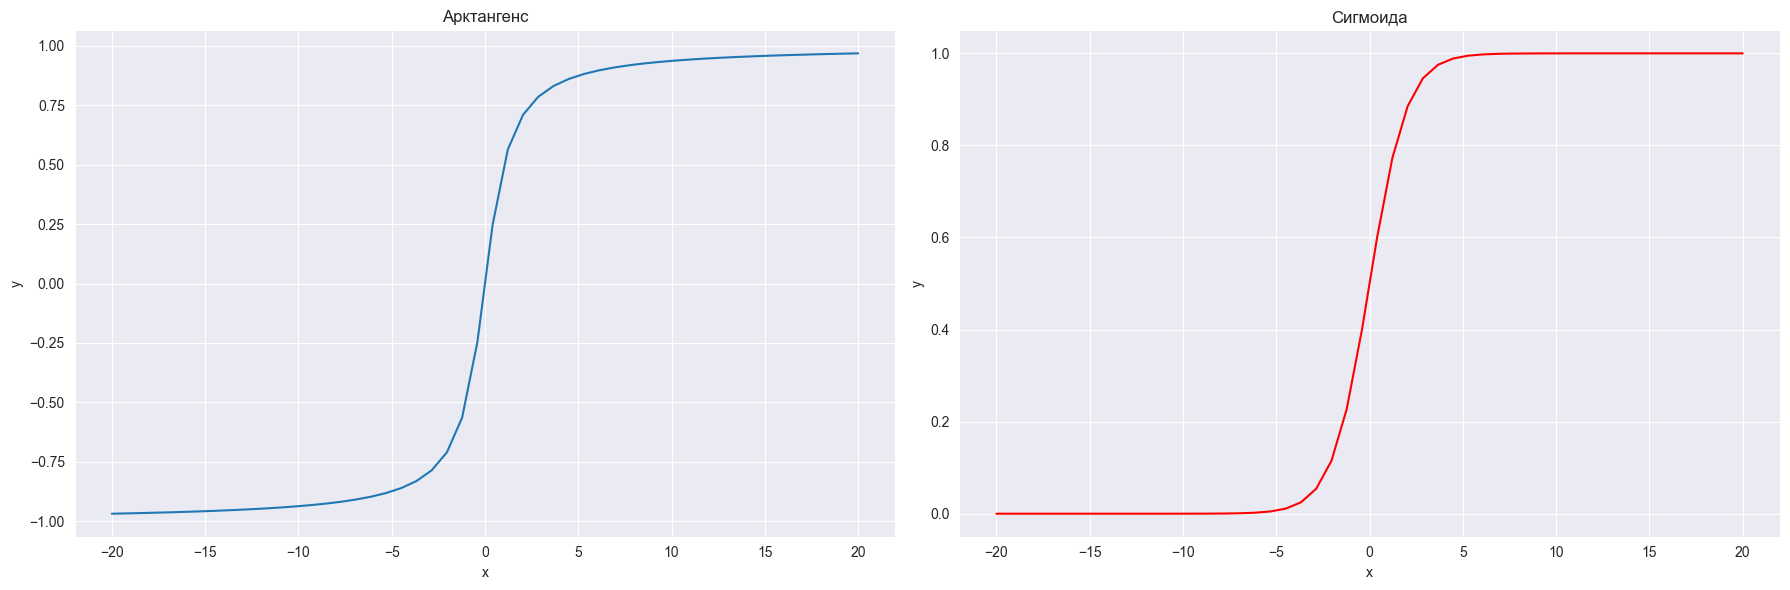

In [27]:
x = np.linspace(-20, 20)
y1 = arctg(x)
y2 = sigmoid(x)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))
ax1.plot(x, y1)
ax1.set_xlabel("x")
ax1.set_ylabel("y")
ax1.set_title("Арктангенс")
ax2.plot(x, y2, color='red')
ax2.set_xlabel("x")
ax2.set_ylabel("y")
ax2.set_title("Сигмоида")
plt.tight_layout()
plt.show()

<div align="center">
  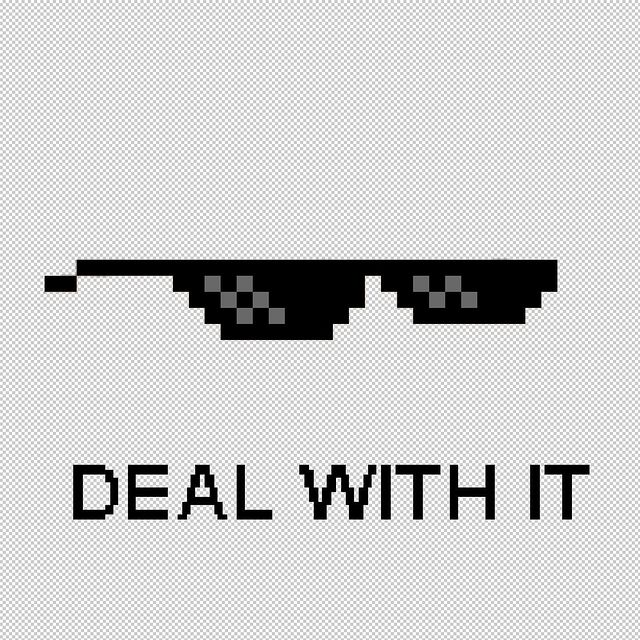
</div>

In [28]:
# Перенесите обученные веса модели из пункта 1.3 в новую модель с модифицированным кодом

# Перенос весов модели из пункта 1.3 и проверка совпадения предсказаний
x_train1, y_train1, x_test1, y_test1 = load_data('dataset1')

# Переобучаем модель из п. 1.3 (алгоритм детерминирован благодаря seed=0, поэтому веса получатся в точности теми же)
logreg_weights = LogisticRegressionWeights(x_train1.shape[1], class_weight="balanced")
logreg_weights.fit(x_train1, y_train1)

# Переносим веса в модель без сигмоиды
logreg_ns = LogisticRegression(dim=x_train1.shape[1])
logreg_ns.w = logreg_weights.w.copy()
logreg_ns.b = logreg_weights.b.copy()

# Сравниваем предсказания
preds_orig = logreg_weights.predict(x_test1)
preds_ns   = logreg_ns.predict(x_test1)

print("Accuracy (с сигмоидой): ", accuracy_score(y_test1, preds_orig))
print("Accuracy (без сигмоиды):", accuracy_score(y_test1, preds_ns))

Accuracy (с сигмоидой):  0.9545454545454546
Accuracy (без сигмоиды): 0.9545454545454546


In [29]:
# Убедитесь, что предсказания модели с модифицированными кодом совпадают с предсказаниями
# модели из пункта 1.3
print("Предсказания совпадают:", np.array_equal(preds_orig, preds_ns))

Предсказания совпадают: True


### 3.2 'Обобщение' логистической регрессии

Напишите многоклассовый классификатор. Обучите его на наборе данных ниже.

In [30]:
x_train, y_train, x_test, y_test = load_data('dataset3')

<b>Ансамбль логистических регрессий.</b> Сложность: супергерой.

In [31]:
"""
Напишите класс, что инкапсулирует в себе `C` логистических регрессий, 
где `C` - количество классов. i-ая логистическая регрессия производит 
бинарную классификацию вида: все остальные классы и i-ый класс.
"""

class MulticlassLogisticRegression:
    def __init__(self, n_classes, dim):
        pass
    
    def predict(self, x):
        # x - numpy массив размерности [N, dim]
        # Возвращается массив целых чисел размерности [N],
        # где i-ый элемент обозначает номер класса для 
        # i-го экземпляра данных в `x`.
        pass
    
    def fit(self, x, y):
        pass

In [32]:
# Создайте и обучите написанный классификатор. Оцените точность модели.


<b>Softmax классификатор.</b> Сложность: математический гений.

In [33]:
"""
Напишите класс классификатора, основанного на функции Softmax.
Алгоритм работы данного классификатора:
x - вектор (экземпляр данных) размерности dim.
W - матрица весов размерности [dim, n_classes].

Ответ классификатора формируется как:
logits = x * W - матричное умножение
p = softmax(logits)
class_id = argmax(p)

Для данного классификатора требуется модифицировать алгоритм обучения в методе fit.

Вспомогательные ресурсы:
https://en.wikipedia.org/wiki/Softmax_function
https://eli.thegreenplace.net/2016/the-softmax-function-and-its-derivative/
"""

class SoftmaxClassificator:
    def __init__(self, n_classes, dim):
        pass
    
    def predict(self, x):
        # x - numpy массив размерности [N, dim]
        # Возвращается массив целых чисел размерности [N],
        # где i-ый элемент обозначает номер класса для 
        # i-го экземпляра данных в `x`.
        pass
    
    def fit(self, x, y):
        pass

In [34]:
# Создайте и обучите написанный классификатор. Оцените точность модели, посчитайте матрицу ошибок (выведите её с помощью matplotlib).


In [35]:
# Создайте и обучите написанный классификатор на наборе данных из задания 1 (опционально). 
# Оцените точность модели, посчитайте матрицу ошибок (выведите её с помощью matplotlib).
